## Time horizon

First things first, we are gonna look at a time window of 1 week, as the crypto market is open everyday, every hour, there are 12 month. Therefore, $k_{1m}=\{1,\cdots,12\}$, im following the paper "Are you trading predictably", where they use a lagged 65 half hours, which corresponds to 5 days of 6.5 hours of trading per day.

Cross-sectional regression

$$ r_{i,t} = \alpha_{k,t} + \gamma_{k,t}r_{i,t-k} + u_{i,k} $$

In [1]:
from binance.client import Client as bnb_client
from datetime import datetime
import pandas as pd
#import statsmodels.api as sm
import numpy as np
import requests
import matplotlib.pyplot as plt

In [2]:
ticker_data = requests.get("https://api.binance.com/api/v3/ticker/24hr").json()
# Convert the API response to a DataFrame
ticker_data = pd.DataFrame(ticker_data)

# Convert volume to numeric values
ticker_data["quoteVolume"] = pd.to_numeric(
    ticker_data["quoteVolume"],
    errors="coerce"
)

top_symbols = (
    ticker_data[ticker_data["symbol"].str.endswith("USDT")]
    .sort_values("quoteVolume", ascending=False)
    .head(1000)["symbol"]
    .tolist()
)

In [3]:
oldest_symbols=top_symbols

In [4]:
import pandas as pd
import requests
import time


def get_all_klines(symbol, interval, start_date, end_date):
    
    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time',
        'open',
        'high',
        'low',
        'close',
        'volume',
        'close_time',
        'quote_volume',
        'trades',
        'taker_buy_base',
        'taker_buy_quote',
        'ignore'
    ]

    start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
    end_time = int(pd.Timestamp(end_date, tz='UTC').timestamp() * 1000)

    if interval.endswith("M")==False:
        interval_time = int(pd.Timedelta(interval).total_seconds() * 1000)

    all_data = []

    while start_time < end_time:
            # Convert dates to milliseconds
        if interval.endswith("M"):
            start_time = int(pd.Timestamp(start_date, tz='UTC').timestamp() * 1000)
        params = {
            'symbol': symbol,
            'interval': interval,
            'startTime': start_time,
            'endTime': end_time,
            'limit': 1000
        }

        response = requests.get(url, params=params)
        response.raise_for_status()

        batch = response.json()

        # Stop when there is no more data
        if not batch:
            break

        # Add this batch to our collection
        all_data.extend(batch)

        # Last candle's opening timestamp
        last_open_time = batch[-1][0]
        if interval.endswith("M"):
            start_date = pd.Timestamp(start_date)
            months = int(interval[:-1]) 
            start_date += pd.DateOffset(months=months)
        # Move to the next millisecond to avoid duplicates
        else:
            start_time = last_open_time + interval_time

        print(f"{symbol}: downloaded {len(all_data)} candles")

        # If fewer than 1000 were returned, we reached the end
        if len(batch) < 1000:
            break

        # Optional: be polite to the API
        time.sleep(0.1)

    # Combine everything into ONE DataFrame
    df = pd.DataFrame(all_data, columns=columns)

    # Remove any possible duplicate timestamps
    df = df.drop_duplicates(subset='open_time')

    # Convert timestamps
    df['open_time'] = pd.to_datetime(
        df['open_time'],
        unit='ms',
        utc=True
    )

    df['close_time'] = pd.to_datetime(
        df['close_time'],
        unit='ms',
        utc=True
    )

    # Convert numeric columns
    for col in ['open', 'high', 'low', 'close', 'volume']:
        df[col] = pd.to_numeric(df[col])

    return df

In [5]:
def get_prices(t_interval, start_date, end_date, until):
    
    symbols = oldest_symbols[:until]

    url = "https://api.binance.com/api/v3/klines"

    columns = [
        'open_time', 'open', 'high', 'low', 'close',
        'volume', 'close_time', 'quote_volume',
        'trades', 'taker_buy_base', 'taker_buy_quote',
        'ignore'
    ]

    # -------------------------------------------------
    # 1. Download prices
    # -------------------------------------------------

    data = {}

    for symbol in symbols:
        df = get_all_klines(symbol, t_interval, start_date, end_date)
        data[symbol] = df
        

    # -------------------------------------------------
    # 2. Construct price and return matrices
    # -------------------------------------------------

    # Use open_time as index so all assets align by time
    px = pd.concat(
        {
            symbol: data[symbol].set_index('open_time')['close']
            for symbol in symbols
        },
        axis=1
    )
    px.to_pickle(f'crypto_{until}_{t_interval}_{start_date}_{end_date}_px.pk')
    return px
    

In [6]:
def find_existing_file(t_interval, start_date, end_date,until):
    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    pattern = f"crypto_{until}_{t_interval}_*_px.pk"

    for path in Path(".").glob(pattern):
        try:
            # crypto_{interval}_{start}_{end}_px.pk
            parts = path.stem.split("_")

            file_start = pd.Timestamp(parts[3])
            file_end = pd.Timestamp(parts[4])

            # Does this file completely cover the requested period?
            if file_start <= start_date and file_end >= end_date:
                return path

        except (ValueError, IndexError):
            continue

    return None

## Trash

In [ ]:
import requests
import pandas as pd
import time

BASE_URL = "https://api.binance.com"

# -------------------------------------------------
# 1. Get all currently tradable USDT spot symbols
# -------------------------------------------------

exchange_info = requests.get(
    f"{BASE_URL}/api/v3/exchangeInfo"
).json()

symbols = [
    s["symbol"]
    for s in exchange_info["symbols"]
    if (
        s["status"] == "TRADING"
        and s["quoteAsset"] == "USDT"
        and s["isSpotTradingAllowed"]
    )
]

print(f"Found {len(symbols)} USDT symbols")


# -------------------------------------------------
# 2. Find the first available daily candle
# -------------------------------------------------

def get_first_kline(symbol):

    params = {
        "symbol": symbol,
        "interval": "1d",
        "startTime": 0,
        "limit": 1
    }

    response = requests.get(
        f"{BASE_URL}/api/v3/klines",
        params=params
    )

    if response.status_code != 200:
        return None

    data = response.json()

    if not data:
        return None

    return pd.to_datetime(
        data[0][0],
        unit="ms",
        utc=True
    )


# -------------------------------------------------
# 3. Determine historical start date for each symbol
# -------------------------------------------------

listing_dates = []

for i, symbol in enumerate(symbols):

    first_date = get_first_kline(symbol)

    if first_date is not None:
        listing_dates.append({
            "symbol": symbol,
            "first_date": first_date
        })

    # Avoid hitting the API too aggressively
    time.sleep(0.05)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(symbols)}")


# -------------------------------------------------
# 4. Volatility 
# -------------------------------------------------




# -------------------------------------------------
# 4. Sort from oldest to newest
# -------------------------------------------------

listing_dates = pd.DataFrame(listing_dates)

listing_dates = listing_dates.sort_values(
    "first_date"
).reset_index(drop=True)

  
# -------------------------------------------------
# 5. Return the symbols
# -------------------------------------------------

symbols = listing_dates["symbol"].tolist()

print("\nOldest symbols:")
print(symbols[:485])

Found 485 USDT symbols
Processed 100/485
Processed 200/485
Processed 300/485
Processed 400/485

Oldest symbols:
['BTCUSDT', 'ETHUSDT', 'BNBUSDT', 'NEOUSDT', 'LTCUSDT', 'QTUMUSDT', 'ADAUSDT', 'XRPUSDT', 'TUSDUSDT', 'IOTAUSDT', 'XLMUSDT', 'ONTUSDT', 'TRXUSDT', 'ETCUSDT', 'ICXUSDT', 'VETUSDT', 'USDCUSDT', 'LINKUSDT', 'ONGUSDT', 'HOTUSDT', 'ZILUSDT', 'ZRXUSDT', 'FETUSDT', 'BATUSDT', 'ZECUSDT', 'IOSTUSDT', 'CELRUSDT', 'DASHUSDT', 'THETAUSDT', 'ENJUSDT', 'ATOMUSDT', 'TFUELUSDT', 'ONEUSDT', 'ALGOUSDT', 'DOGEUSDT', 'DUSKUSDT', 'ANKRUSDT', 'WINUSDT', 'MTLUSDT', 'CVCUSDT', 'CHZUSDT', 'BANDUSDT', 'XTZUSDT', 'RVNUSDT', 'HBARUSDT', 'STXUSDT', 'KAVAUSDT', 'ARPAUSDT', 'IOTXUSDT', 'RLCUSDT', 'BCHUSDT', 'FTTUSDT', 'EURUSDT', 'OGNUSDT', 'LSKUSDT', 'BNTUSDT', 'MBLUSDT', 'COTIUSDT', 'CTSIUSDT', 'HIVEUSDT', 'CHRUSDT', 'KNCUSDT', 'COMPUSDT', 'SCUSDT', 'ZENUSDT', 'SNXUSDT', 'VTHOUSDT', 'DGBUSDT', 'DCRUSDT', 'STORJUSDT', 'MANAUSDT', 'YFIUSDT', 'JSTUSDT', 'SOLUSDT', 'SANDUSDT', 'CRVUSDT', 'DOTUSDT', 'NMRUSDT',

In [ ]:
oldest_symbols=symbols

In [ ]:
top_symbols

['USDCUSDT',
 'BTCUSDT',
 'ETHUSDT',
 'SOLUSDT',
 'XRPUSDT',
 'ZECUSDT',
 'USD1USDT',
 'BNBUSDT',
 'REUSDT',
 'DOGEUSDT',
 'SUIUSDT',
 'PEPEUSDT',
 'RLUSDUSDT',
 'PUMPUSDT',
 'TRXUSDT',
 'NEARUSDT',
 'UUSDT',
 'LINKUSDT',
 'ENAUSDT',
 'TUTUSDT',
 'ADAUSDT',
 'TRUMPUSDT',
 'ONGUSDT',
 'PENGUUSDT',
 'AAVEUSDT',
 'ZROUSDT',
 'SNDKBUSDT',
 'TAOUSDT',
 'CRCLBUSDT',
 'FDUSDUSDT',
 'WLDUSDT',
 'XLMUSDT',
 'UNIUSDT',
 'LTCUSDT',
 'POLUSDT',
 'PROMUSDT',
 'AVAXUSDT',
 'XAUTUSDT',
 'HBARUSDT',
 'ONDOUSDT',
 'PAXGUSDT',
 'DASHUSDT',
 'INJUSDT',
 'XPLUSDT',
 'EURUSDT',
 'SPCXBUSDT',
 'ASTERUSDT',
 'FETUSDT',
 'BMTUSDT',
 'ACEUSDT',
 'PYTHUSDT',
 'EURIUSDT',
 'GRAMUSDT',
 'BCHUSDT',
 'SNXXBUSDT',
 'MSTRBUSDT',
 'STXUSDT',
 'VIRTUALUSDT',
 'UTKUSDT',
 'MUBUSDT',
 'SHIBUSDT',
 'JTOUSDT',
 'HOLOUSDT',
 'WIFUSDT',
 'FILUSDT',
 'TONUSDT',
 'WLFIUSDT',
 'ETHFIUSDT',
 'RENDERUSDT',
 'ONTUSDT',
 'ICPUSDT',
 'SKHYBUSDT',
 'DOTUSDT',
 'FFUSDT',
 'APTUSDT',
 'BONKUSDT',
 'TLMUSDT',
 'SPKUSDT',
 'ARBUSDT',
 'H

In [ ]:
def momentum_reversal(t_max,k_max,t_interval):
    symbols = symbols[:485]
    url = "https://api.binance.com/api/v3/klines"


    columns = [
    'open_time',
    'open',
    'high',
    'low',
    'close',
    'volume',
    'close_time',
    'quote_volume',
    'trades',
    'taker_buy_base',
    'taker_buy_quote',
    'ignore'
    ]

    data = {}

    for symbol in symbols:

        params = {
        'symbol': symbol,
        'interval': t_interval,
        'limit': t_max
        }

        response = requests.get(url, params=params)
        response.raise_for_status()

        df = pd.DataFrame(response.json(), columns=columns)

    # Convert timestamps
        df['open_time'] = pd.to_datetime(
        df['open_time'],
        unit='ms',
        utc=True
        )

        df['close_time'] = pd.to_datetime(
        df['close_time'],
        unit='ms',
        utc=True
        )

    # Convert prices to numeric
        for col in ['open', 'high', 'low', 'close', 'volume']:
            df[col] = pd.to_numeric(df[col])

        data[symbol] = df

    px = pd.DataFrame({symbol: data[symbol]['close'] for symbol in symbols})
    ret = px.pct_change()
    ret_lag = {}
    for k in range(1,k_max+1):
        ret_lag[k] = ret.shift(k)
    ret_lag_az = {}
    for t in ret.index:
        x = {}
        for k in range(1,k_max+1):
            x[k] = ret_lag[k].iloc[t]
        ret_lag_az[t] = pd.DataFrame(x, index=symbols)
    betas={}
    for t in range(2,t_max):
        y_t = ret.loc[t]
        for k in range(1,k_max+1):
            if t-k >= 1:
                x_t = ret_lag_az[t][k].dropna()
                print(x_t)
            df = pd.concat([y_t.rename('y'), x_t.rename('x')],axis=1).dropna()
            X = sm.add_constant(df['x'])
            model = sm.OLS(df['y'], X).fit()
            betas[(t,k)] = model.params
    gammas_mean={}
    for k in range(1,k_max+1):
        gammas=[]
        for t in range(2,t_max):
            gamma = betas[(t,k)][1]
            gammas.append(gamma)
        gammas_mean[k] = np.mean(gammas)
    gammas_mean = pd.DataFrame(gammas_mean, index=['gamma']).T
    gammas_mean_normalized=gammas_mean/gammas_mean.max()*100
    gammas_mean_normalized.plot.bar()

## Momentum and Reversal

In [7]:
import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import matplotlib.pyplot as plt
from pathlib import Path


def momentum_reversal(k_max, t_interval, start_date, end_date,until):
    
    filename = find_existing_file(t_interval, start_date, end_date,until)

    if filename is not None:
        print(f"Using existing data: {filename}")
        px = pd.read_pickle(filename).loc[start_date:end_date]
    else:
        print("Downloading data...")
        px = get_prices(t_interval, start_date, end_date,until)

    # Return r(i,t)
    ret = px.pct_change()

    # -------------------------------------------------
    # 3. Cross-sectional regressions
    # -------------------------------------------------

    betas = {}

    for k in range(1, k_max + 1):

        # r(i,t-k)
        ret_lag = ret.shift(k)

        # Need at least k previous observations
        for t in range(k + 1, len(ret)):

            # Current cross-section: r(i,t)
            y_t = ret.iloc[t]

            # Lagged cross-section: r(i,t-k)
            x_t = ret_lag.iloc[t]

            # Combine and remove missing values
            regression_data = pd.concat(
                [y_t.rename('y'), x_t.rename('x')],
                axis=1
            ).dropna()

            # Skip if insufficient assets
            if len(regression_data) < 3:
                continue

            # r(i,t) = alpha(k,t) + gamma(k,t) * r(i,t-k) + u(i,t)
            X = sm.add_constant(regression_data['x'])
            model = sm.OLS(regression_data['y'], X).fit()

            betas[(ret.index[t], k)] = {
                'alpha': model.params['const'],
                'gamma': model.params['x'],
                't_stat': model.tvalues['x'],
                'n_obs': len(regression_data)
            }

    # -------------------------------------------------
    # 4. Average gammas across time
    # -------------------------------------------------

    results = []


    for k in range(1, k_max + 1):

        gammas = [
            values['gamma']
            for (t, lag), values in betas.items()
            if lag == k
        ]


        if len(gammas) > 0:

            mean_gamma = np.mean(gammas)

            results.append({
                'lag': k,
                'mean_gamma': mean_gamma,
                'n_periods': len(gammas)
            })

    results = pd.DataFrame(results).set_index('lag')

    # -------------------------------------------------
    # 5. Plot gammas_mean.abs().sum()
    # -------------------------------------------------
    gammas_mean_normalized=results['mean_gamma']/results['mean_gamma'].abs().sum()
    gammas_mean_normalized.plot(
        figsize=(10, 5),
        kind='bar'
    )

    plt.xlabel('Lag k (30-minute periods)')
    plt.ylabel('Average gamma')
    plt.title('Average Cross-Sectional Return Response by Lag')
    plt.show()

    return betas, ret

## Volatility band

In [19]:
dates=['2017-01-01','2020-03-15','2022-12-31','2024-12-31','2026-09-14']

In [2]:
ret=get_prices('8h','2017-01-01','2026-09-14',10000).pct_change()

NameError: name 'get_prices' is not defined

In [21]:
ret.to_pickle(f'crypto_10000_8h_2017-01-01_2026-09-14_ret.pk')

In [9]:
filename=f'crypto_1000_30m_2026-02-25_2026-08-28_px.pk'
ret = pd.read_pickle(filename).pct_change()

C:\Users\parra\AppData\Local\Temp\ipykernel_15412\892275981.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  ret = pd.read_pickle(filename).pct_change()


In [13]:
ret=pd.read_pickle(f'crypto_1000_8h_2017-01-01_2026-09-14_ret.pk')

In [10]:
def get_vol(start_date,end_date):
    vol=ret.loc[start_date:end_date].std()*np.sqrt(365*3)
    return np.log10(vol)

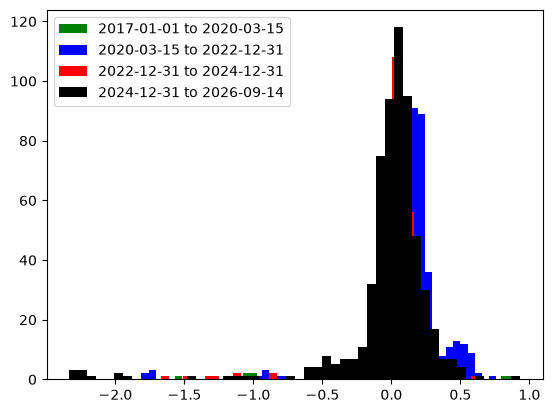

In [11]:
col = ['g','b','r','k']
for i in range(0,len(dates)-1):
    x=get_vol(dates[i],dates[i+1])
    x = x.replace(-np.inf, np.nan)
    plt.hist(x,bins=50,color=col[i],label=f'{dates[i]} to {dates[i+1]}')
    plt.legend()
plt.show()

In [14]:
vol=ret.rolling(window=700, min_periods=90).std()*np.sqrt(365*3)

In [15]:
vol = vol.iloc[90:]

In [16]:
was_dead = (vol == 0)
revived = was_dead.shift(1).fillna(False) & (vol > 0)
print(revived.sum().sum(), 'coin-days where a previously-dead coin came back')

0 coin-days where a previously-dead coin came back


In [17]:
perc = {}
for i in range(1,100):
    perc[i] = vol.apply(lambda row: np.nanpercentile(row, i),axis=1)
perc=pd.DataFrame(perc)

In [18]:
def densest_band(perc, mass=50):
    """
    perc: DataFrame, rows = days, columns = 1..99 (percentile values).
    mass: how many percentile points wide the band should be (e.g. 50
          for a 50%-mass band, 90 for a 90%-mass band).

    Returns a DataFrame with lo_pct, hi_pct, lo_val, hi_val per day —
    the narrowest (densest) interval of that mass, found independently
    for each day.
    """
    cols = perc.columns.to_numpy()          # should be 1..99
    vals = perc.to_numpy()                  # shape (n_days, 99)

    # vals[:, mass:] are percentiles (mass+1)..99
    # vals[:, :-mass] are percentiles 1..(99-mass)
    diffs = vals[:, mass:] - vals[:, :-mass]     # shape (n_days, 99-mass)
    best_start_idx = np.argmin(diffs, axis=1)    # index into the "lo" side

    lo_pct = cols[best_start_idx]
    hi_pct = lo_pct + mass

    lo_val = vals[np.arange(len(vals)), best_start_idx]
    hi_val = vals[np.arange(len(vals)), best_start_idx + mass]

    return pd.DataFrame({
        'lo_pct': lo_pct, 'hi_pct': hi_pct,
        'lo_val': lo_val, 'hi_val': hi_val,
    }, index=perc.index)

In [19]:
def plot_band(mass, band50):
    # see if the band is stable or drifts over time
    print(band50.head())
    plt.figure(figsize=(12,5))
    plt.plot(band50.index, band50['lo_pct'], label='lower bound (percentile)')
    plt.plot(band50.index, band50['hi_pct'], label='upper bound (percentile)')
    plt.ylabel('Percentile')
    plt.title(f'Densest {mass}%-mass band, per day')
    plt.legend()
    plt.show()
    # summary: what band shows up most often?
    print(band50[['lo_pct','hi_pct']].mode())
    print(band50[['lo_pct','hi_pct']].median())

In [20]:
min_ent=[]
mass_ent=range(5,80,1)
for mass in mass_ent:
    band50 = densest_band(perc, mass)
    
    # membership matrix: True if that coin's vol falls inside that day's densest 50% band
    lo = band50['lo_val'].values.reshape(-1, 1)
    hi = band50['hi_val'].values.reshape(-1, 1)
    inside = (vol.values >= lo) & (vol.values <= hi)
    inside = pd.DataFrame(inside, index=vol.index, columns=vol.columns)

    # a coin "enters" on a day it's inside now but wasn't the day before
    # a coin "leaves" on a day it's outside now but was inside the day before
    entered = inside & ~inside.shift(1).fillna(False)
    left    = ~inside & inside.shift(1).fillna(False)

    entries_per_coin = entered.sum(axis=0)   # how many times each coin entered
    exits_per_coin   = left.sum(axis=0)      # how many times each coin left

    summary = pd.DataFrame({
        'entries': entries_per_coin,
        'exits': exits_per_coin,
    }).sort_values('entries', ascending=False)

    print(summary)

    # coins that entered/left more than once = "in and out multiple times"
    multi_flip = summary[summary['entries'] > 1]
    
    min_ent.append(len(multi_flip))

             entries  exits
CHRUSDT         1124    231
ENJUSDT          990    245
ALICEUSDT        978    140
QTUMUSDT         957    221
DATAUSDT         918    184
...              ...    ...
YFIDOWNUSDT        0      0
ETHBEARUSDT        0      0
BTCUSDT            0      0
EOSBEARUSDT        0      0
USDCUSDT           0      0

[749 rows x 2 columns]
             entries  exits
CHRUSDT         1382    229
ENJUSDT         1230    227
TLMUSDT         1196    193
QTUMUSDT        1127    209
AAVEUSDT        1118    190
...              ...    ...
EOSBULLUSDT        0      0
BEARUSDT           0      0
ETHBEARUSDT        0      0
EOSBEARUSDT        0      0
USDCUSDT           0      0

[749 rows x 2 columns]
             entries  exits
CHRUSDT         1674    227
ENJUSDT         1466    238
TLMUSDT         1382    199
THETAUSDT       1322    223
DATAUSDT        1253    201
...              ...    ...
USDSOLDUSDT        0      0
ETHBEARUSDT        0      0
USD1USDT           0      0


KeyboardInterrupt: 

<Axes: >

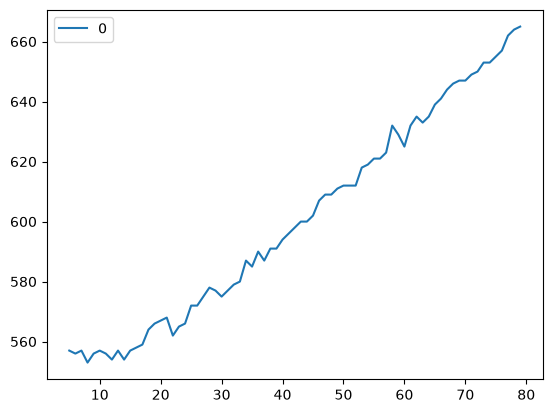

In [ ]:
ex=pd.DataFrame(min_ent,mass_ent)
ex.plot()

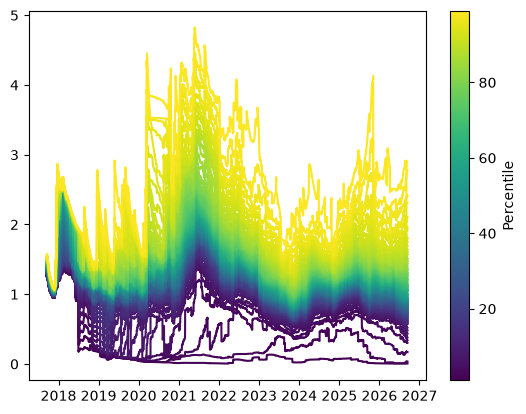

In [ ]:
import matplotlib.colors as mcolors

fig, ax = plt.subplots()

cmap = plt.get_cmap('viridis')
# or: cmap = matplotlib.colormaps['viridis']

norm = mcolors.Normalize(vmin=1, vmax=99)

for i in range(1, 100):
    ax.plot(perc[i], color=cmap(norm(i)))

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Percentile')

plt.show()

## SIGNAL


Using existing data: crypto_1000_30m_2025-11-01_2025-12-31_px.pk


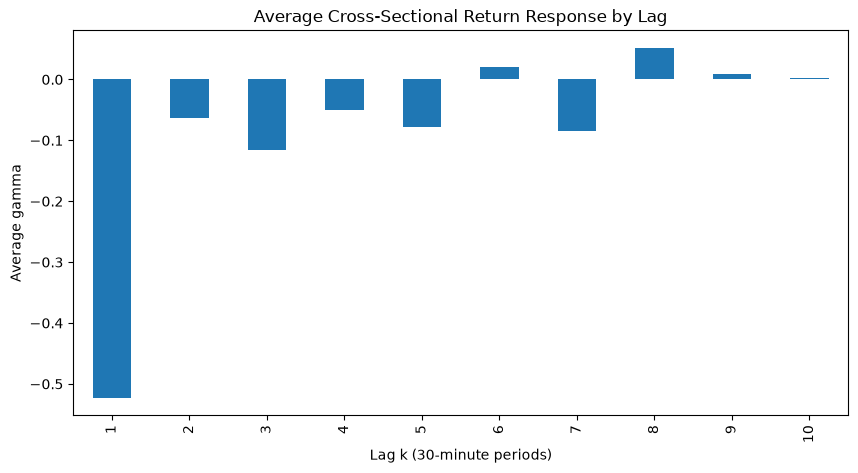

In [8]:
k_max=10
betas, ret = momentum_reversal(k_max,'30m', '2025-11-01', '2025-12-31', 1000)

In [135]:
betas

{(Timestamp('2025-11-01 01:00:00+0000', tz='UTC'),
  1): {'alpha': np.float64(0.002509199006136294), 'gamma': np.float64(0.13111106038685919), 't_stat': np.float64(3.3171678541795693), 'n_obs': 436},
 (Timestamp('2025-11-01 01:30:00+0000', tz='UTC'),
  1): {'alpha': np.float64(-0.004972235824815373), 'gamma': np.float64(-0.13338939673029468), 't_stat': np.float64(-3.229838301199289), 'n_obs': 436},
 (Timestamp('2025-11-01 02:00:00+0000', tz='UTC'),
  1): {'alpha': np.float64(-0.00096753224504629), 'gamma': np.float64(-0.005869355318804101), 't_stat': np.float64(-0.1376788588874684), 'n_obs': 436},
 (Timestamp('2025-11-01 02:30:00+0000', tz='UTC'),
  1): {'alpha': np.float64(0.006735554122288956), 'gamma': np.float64(-0.475387830482326), 't_stat': np.float64(-7.29129879758167), 'n_obs': 436},
 (Timestamp('2025-11-01 03:00:00+0000', tz='UTC'),
  1): {'alpha': np.float64(0.0034475719298877328), 'gamma': np.float64(-0.044277105015467895), 't_stat': np.float64(-1.236882328676947), 'n_obs': 

In [139]:
df = pd.DataFrame.from_dict(betas, orient="index")
df.index.names = ["t", "k"]

gammas = (df["gamma"].unstack("t")
         .reindex(index=range(1, k_max + 1), columns=ret.index))

In [144]:
gammas_norm=gammas/gammas.abs().sum()
gammas_norm

open_time,2025-11-01 00:00:00+00:00,2025-11-01 00:30:00+00:00,2025-11-01 01:00:00+00:00,2025-11-01 01:30:00+00:00,2025-11-01 02:00:00+00:00,2025-11-01 02:30:00+00:00,2025-11-01 03:00:00+00:00,2025-11-01 03:30:00+00:00,2025-11-01 04:00:00+00:00,2025-11-01 04:30:00+00:00,...,2025-12-30 19:30:00+00:00,2025-12-30 20:00:00+00:00,2025-12-30 20:30:00+00:00,2025-12-30 21:00:00+00:00,2025-12-30 21:30:00+00:00,2025-12-30 22:00:00+00:00,2025-12-30 22:30:00+00:00,2025-12-30 23:00:00+00:00,2025-12-30 23:30:00+00:00,2025-12-31 00:00:00+00:00
k,,,,,,,,,,,,,,,,,,,,,
1,NaN,NaN,1.0,-0.764286,-0.081773,-0.400367,-0.100266,0.162583,0.061536,0.114766,...,-0.212252,-0.358350,-0.183828,-0.247475,-0.293061,-0.020581,-0.185089,-0.176455,0.167896,-0.112031
2,NaN,NaN,NaN,-0.235714,-0.373424,-0.198266,0.160722,0.179781,0.175432,0.007969,...,-0.017657,-0.021868,-0.065057,-0.071097,0.202037,0.284830,0.191056,-0.042451,-0.117611,-0.092947
3,NaN,NaN,NaN,NaN,0.544803,0.321656,0.089877,-0.058466,0.081111,-0.118487,...,-0.143984,-0.004436,0.022398,0.094984,0.119642,0.062959,-0.162912,-0.277689,0.008783,-0.019626
4,NaN,NaN,NaN,NaN,NaN,0.079712,0.122807,0.196038,-0.165338,0.117736,...,-0.094329,0.207560,-0.040784,0.126320,-0.026791,0.085707,0.034075,0.204878,-0.257684,0.330642
5,NaN,NaN,NaN,NaN,NaN,NaN,0.526327,0.227353,0.074553,-0.169616,...,-0.112017,-0.014258,-0.015529,0.127819,-0.169369,0.001302,-0.081524,-0.142870,0.219393,0.031239
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.175780,0.199514,-0.222443,...,-0.094762,-0.041140,0.160856,0.161927,0.011693,0.352410,0.050651,-0.008497,-0.098235,-0.043009
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.242516,0.240287,...,0.130454,0.026069,-0.116361,0.019935,-0.000402,0.057762,-0.125810,-0.019891,-0.049631,0.088674
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.008697,...,0.076463,0.060775,0.290014,0.097958,-0.083479,-0.046568,-0.020533,0.047948,0.002462,0.139580
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,-0.093835,-0.105519,-0.045556,-0.013845,-0.078539,0.072231,0.032168,0.008237,-0.024586,0.052568


In [162]:
ret_t_i=ret.rolling(window=k_max).sum()
z_ret_t=(ret_t_i.sub(ret_t_i.mean(axis=1), axis=0)).div(ret_t_i.std(axis=1), axis=0)

In [1]:
gammas_norm.iloc[99].plot()

NameError: name 'gammas_norm' is not defined

In [164]:
gammas_norm.T

k,1,2,3,4,5,6,7,8,9,10
open_time,,,,,,,,,,
2025-11-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 00:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 01:00:00+00:00,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 01:30:00+00:00,-0.764286,-0.235714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 02:00:00+00:00,-0.081773,-0.373424,0.544803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2025-12-30 22:00:00+00:00,-0.020581,0.284830,0.062959,0.085707,0.001302,0.352410,0.057762,-0.046568,0.072231,-0.015650
2025-12-30 22:30:00+00:00,-0.185089,0.191056,-0.162912,0.034075,-0.081524,0.050651,-0.125810,-0.020533,0.032168,-0.116182
2025-12-30 23:00:00+00:00,-0.176455,-0.042451,-0.277689,0.204878,-0.142870,-0.008497,-0.019891,0.047948,0.008237,-0.071084


In [161]:
z_ret_t

,USDCUSDT,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT,USD1USDT,ENAUSDT,ZECUSDT,RLUSDUSDT,TRUMPUSDT,...,KEEPUSDT,USDSBUSDT,ERDUSDT,BTTUSDT,USDSOLDUSDT,BCHSVUSDT,BCHABCUSDT,PAXUSDT,VENUSDT,BCCUSDT
open_time,,,,,,,,,,,,,,,,,,,,,
2025-11-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 00:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 01:30:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-11-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-30 22:00:00+00:00,0.105737,-0.061902,-0.178680,-0.466641,-0.096922,0.098340,-1.091766,0.110345,NaN,-0.111103,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-12-30 22:30:00+00:00,0.060802,0.090072,-0.152842,-0.129658,-0.065423,0.045212,-1.146241,-1.276226,NaN,-0.151894,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-12-30 23:00:00+00:00,-0.056899,0.111850,-0.125616,0.165664,-0.144152,-0.065328,-0.731485,-1.369480,NaN,-0.192497,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
def score(gammas,ret,k_max):
    x=[]
    for k in range(1,k_max+1):
        ret_roll_k = ret.rolling(window = k).sum()
        z_ret=(ret-ret_roll_k.mean(axis=1))/ret_roll_k.std(axis=1)
        x.append(gammas_mean * z_ret)
    score_t = np.sum(x,axis=0)
    return score_t

In [11]:
score(gammas_mean, ret, 10).plot()

C:\Users\parra\AppData\Local\Temp\ipykernel_4568\2508607524.py:6: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  x.append(gammas_mean * z_ret)
C:\Users\parra\AppData\Local\Temp\ipykernel_4568\2508607524.py:6: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  x.append(gammas_mean * z_ret)
C:\Users\parra\AppData\Local\Temp\ipykernel_4568\2508607524.py:6: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  x.append(gammas_mean * z_ret)
C:\Users\parra\AppData\Local\Temp\ipykernel_4568\2508607524.py:6: RuntimeWarning: '<' not supported between instances of 'int' and 'Timestamp', sort order is undefined for incomparable objects.
  x.append(gammas_mean * z_ret)
C:\Users\parra\AppData\Local\Temp\ipykernel_4568\2508607524.py:6: RuntimeWarning: '<' not suppor

AttributeError: 'numpy.ndarray' object has no attribute 'plot'

### Theoretical highest sharpe

In [83]:
ret = ret.dropna(axis=0, how="all") 
ret = ret.dropna(axis=1, how="all") 
ret = ret.fillna(0.0)

In [92]:
def optimal_wights(ret):
    corr = ret.corr()
    vols = np.diag(np.std(ret,axis=0))
    sigma = vols @ corr.values @ vols
    mu = ret.mean()
    wgt = np.linalg.inv(sigma) @ mu
    wgt = wgt/np.abs(wgt).sum()
    return wgt

In [94]:
strat_wgt=optimal_wights(ret)
strat_ret=(strat_wgt*ret).sum(axis=1)
#strat_ret.cumsum().plot
strat_sharpe = strat_ret.mean()/strat_ret.std()*factor
strat_sharpe

np.float64(39.85651862848182)

## Start

In [1]:
def annualization_factor(interval: str, asset_type: str = "crypto", trading_hours_per_day: float = 6.5):

    s = interval.strip().lower()
    if s.endswith("m") and not s.endswith("min"):
        s = s[:-1] + "min"

    delta = pd.Timedelta(s)
    bar_hours = delta.total_seconds() / 3600

    if asset_type == "crypto":
        days_per_year = 365
        hours_per_day = 24
    elif asset_type == "stock":
        days_per_year = 252
        hours_per_day = trading_hours_per_day
    else:
        raise ValueError("asset_type must be 'crypto' or 'stock'")

    # daily or longer bars
    if bar_hours >= 24:
        bar_days = bar_hours / 24
        periods_per_year = days_per_year / bar_days
    else:
        bars_per_day = hours_per_day / bar_hours
        periods_per_year = days_per_year * bars_per_day

    return np.sqrt(periods_per_year)


Using existing data: crypto_1000_30m_2025-11-01_2025-12-31_px.pk


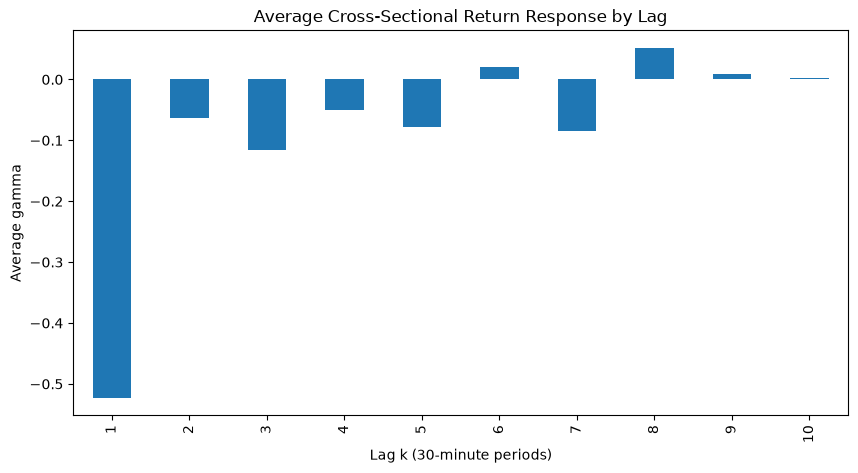

In [ ]:
interval='30m'
gammas_mean, ret = momentum_reversal(10, interval, '2025-11-01', '2025-12-31', 1000)


In [ ]:
factor=annualization_factor(interval,'crypto')